<a href="https://colab.research.google.com/github/Harish150707/Stock_Price_Prediction/blob/main/Stock_Price_Prediction%5BHarish%20T%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running on device: cpu
Loaded 1259 trading days for AAPL.
Training model...
Epoch [01/25] - Loss: 0.102109
Epoch [05/25] - Loss: 0.002853
Epoch [10/25] - Loss: 0.001795
Epoch [15/25] - Loss: 0.001615
Epoch [20/25] - Loss: 0.001230
Epoch [25/25] - Loss: 0.001173

 Results for AAPL 
RMSE:                $10.72
MAE:                 $9.42
MAPE:                5.71%
Directional Accuracy: 49.21%


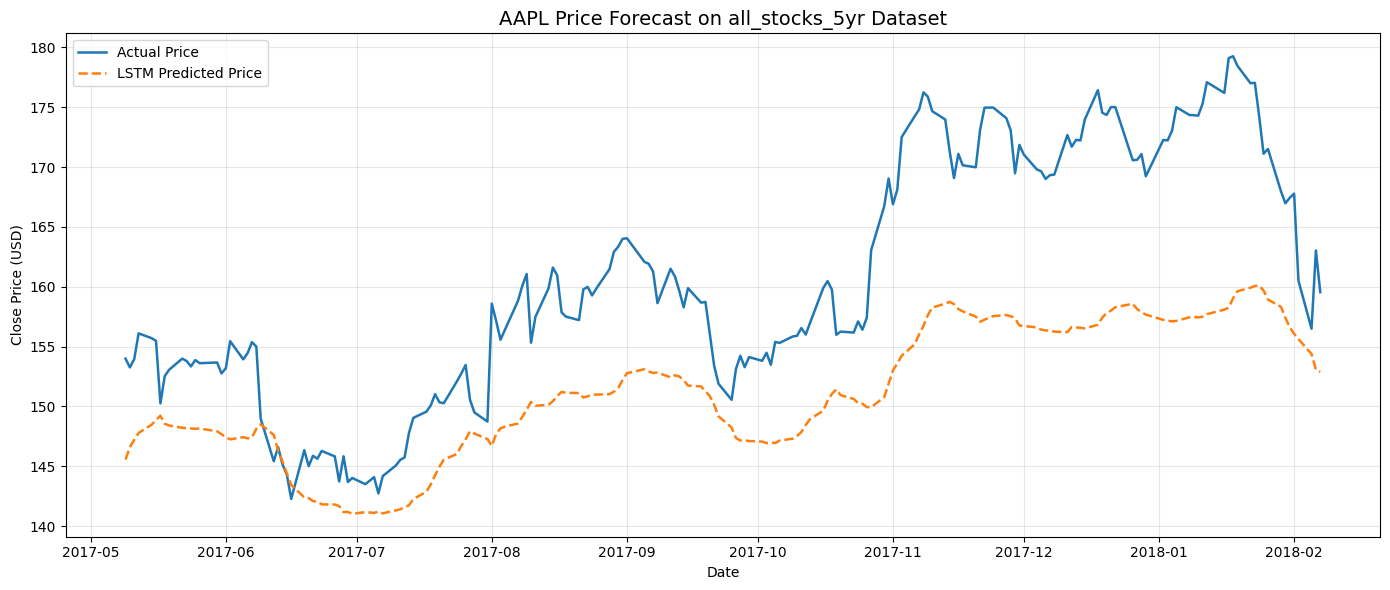

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Check GPU availability in Colab
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)

# ==========================================
# 1. LOAD & FILTER SPECIFIC STOCK
# ==========================================
csv_path = "all_stocks_5yr.csv"
full_df = pd.read_csv(csv_path)

# Pick any ticker present in the 'Name' column: e.g., 'AAPL', 'GOOGL', 'AMZN', 'MSFT'
TARGET_TICKER = "AAPL"
df = full_df[full_df["Name"] == TARGET_TICKER].copy()

# Sort chronologically by date
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Handle column naming variations (lowercase in this Kaggle set)
df.rename(columns={
    "date": "Date",
    "open": "Open",
    "high": "High",
    "low": "Low",
    "close": "Close",
    "volume": "Volume"
}, inplace=True)

print(f"Loaded {len(df)} trading days for {TARGET_TICKER}.")

# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================
# 12-day and 26-day EMA
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()
df["EMA_26"] = df["Close"].ewm(span=26, adjust=False).mean()
df["MACD"] = df["EMA_12"] - df["EMA_26"]

# 14-day RSI
delta = df["Close"].diff()
gain = delta.where(delta > 0, 0.0).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0.0)).rolling(window=14).mean()
rs = gain / (loss + 1e-9)
df["RSI"] = 100.0 - (100.0 / (1.0 + rs))

# Daily Log Returns
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# Drop NaN warmup rows
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

feature_cols = ["Close", "Volume", "EMA_12", "RSI", "MACD", "Log_Return"]

# ==========================================
# 3. SPLIT & SCALE (NO LOOKAHEAD LEAKAGE)
# ==========================================
LOOKBACK = 60
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx][feature_cols]
test_df = df.iloc[split_idx:][feature_cols]

feature_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler = MinMaxScaler(feature_range=(0, 1))

scaled_train = feature_scaler.fit_transform(train_df.values)
target_scaler.fit(train_df[["Close"]].values)

scaled_test = feature_scaler.transform(test_df.values)

def create_sequences(data, lookback=60, target_col_idx=0):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i, :])
        y.append(data[i, target_col_idx])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(scaled_train, lookback=LOOKBACK)
X_test, y_test = create_sequences(scaled_test, lookback=LOOKBACK)

class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(StockDataset(X_train, y_train), batch_size=32, shuffle=True)
test_loader = DataLoader(StockDataset(X_test, y_test), batch_size=32, shuffle=False)

# ==========================================
# 4. PYTORCH LSTM ARCHITECTURE
# ==========================================
class StockLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2):
        super(StockLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        return self.fc(out[:, -1, :]).squeeze(-1)

model = StockLSTM(input_dim=len(feature_cols)).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 5. TRAINING LOOP
# ==========================================
EPOCHS = 25
print("Training model...")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch_x.size(0)

    if epoch % 5 == 0 or epoch == 1:
        avg_loss = total_loss / len(train_loader.dataset)
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] - Loss: {avg_loss:.6f}")

# ==========================================
# 6. EVALUATION & INVERSE SCALING
# ==========================================
model.eval()
raw_preds = []

with torch.no_grad():
    for batch_x, _ in test_loader:
        batch_x = batch_x.to(device)
        preds = model(batch_x)
        raw_preds.extend(preds.cpu().numpy())

pred_prices = target_scaler.inverse_transform(np.array(raw_preds).reshape(-1, 1))
actual_prices = target_scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = math.sqrt(mean_squared_error(actual_prices, pred_prices))
mae = mean_absolute_error(actual_prices, pred_prices)
mape = np.mean(np.abs((actual_prices - pred_prices) / actual_prices)) * 100

actual_dir = np.sign(actual_prices[1:] - actual_prices[:-1])
pred_dir = np.sign(pred_prices[1:] - actual_prices[:-1])
dir_accuracy = np.mean(actual_dir == pred_dir) * 100

print("\n" + "="*30)
print(f" Results for {TARGET_TICKER} ")
print("="*30)
print(f"RMSE:                ${rmse:.2f}")
print(f"MAE:                 ${mae:.2f}")
print(f"MAPE:                {mape:.2f}%")
print(f"Directional Accuracy: {dir_accuracy:.2f}%")

# ==========================================
# 7. PLOT PREDICTIONS
# ==========================================
test_dates = df.iloc[split_idx + LOOKBACK:]["Date"]

plt.figure(figsize=(14, 6))
plt.plot(test_dates, actual_prices, label="Actual Price", color="#1f77b4", linewidth=1.8)
plt.plot(test_dates, pred_prices, label="LSTM Predicted Price", color="#ff7f0e", linestyle="--", linewidth=1.8)
plt.title(f"{TARGET_TICKER} Price Forecast on all_stocks_5yr Dataset", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Close Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()